# Pakistan Auto Industry (PAMA) – Big Data Analytics, Data Warehousing & Mining
**Data:** PAMA monthly vehicle *production* and *sales*, July 2007 – May 2025 (`pama.xlsx`).

**Pipeline:** 1 Load → 2 Clean (ETL) → 3 Data Warehouse (star schema, Parquet) → 4 Analytics (Spark SQL) → 5 Mining A (KMeans) → 6 Mining B (forecast) → 7 Findings.


Pakistan's auto year is July–June, so we use a *fiscal year* (FY2024 = Jul 2023 – Jun 2024).

In [1]:
!pip -q install pyspark openpyxl

In [2]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window

plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.width", 160)

**Load The Dataset**

In [3]:
FILE = "pama.xlsx"
if not os.path.exists(FILE):
    from google.colab import files
    up = files.upload()
    FILE = list(up.keys())[0]

raw = pd.read_excel(FILE).iloc[:, :9]
raw.columns = ["vehicle", "type", "month", "year", "value",
               "vehicle_2", "model", "engine_class", "category"]
print("Rows loaded:", len(raw))
raw.head()

Saving pama.xlsx to pama.xlsx
Rows loaded: 17722


,vehicle,type,month,year,value,vehicle_2,model,engine_class,category
0,Honda Civic,Prod.,Jul,2007,554.0,Honda Civic,Honda Cars (Civic & City),1300cc and Above,CARS
1,Honda Civic,Prod.,Aug,2007,533.0,Honda Civic,Honda Cars (Civic & City),1300cc and Above,CARS
2,Honda Civic,Prod.,Sep,2007,405.0,Honda Civic,Honda Cars (Civic & City),1300cc and Above,CARS
3,Honda Civic,Prod.,Oct,2007,662.0,Honda Civic,Honda Cars (Civic & City),1300cc and Above,CARS
4,Honda Civic,Prod.,Nov,2007,423.0,Honda Civic,Honda Cars (Civic & City),1300cc and Above,CARS


## 2. Clean the data (ETL – Transform)
The raw file has several problems. Each step below fixes one of them.

In [4]:
df = raw.copy()

# 2.1 Values: some cells are empty placeholders -> remove them
df["value"] = pd.to_numeric(df["value"], errors="coerce")
n0 = len(df); df = df.dropna(subset=["value"])
print(f"2.1 Removed {n0 - len(df)} empty placeholder rows")

# 2.2 Type: 'Prod' and 'Prod.' mean the same thing
df["measure"] = np.where(df["type"].astype(str).str.lower().str.startswith("prod"), "production", "sales")

# 2.3 Month names are inconsistent (Jul / July, Sep / Sept, Apr / April) -> use first 3 letters
MONTHS = {m: i + 1 for i, m in enumerate(["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"])}
df["month_num"] = df["month"].astype(str).str.strip().str.lower().str[:3].map(MONTHS)
assert df["month_num"].notna().all(), "unknown month name found"
df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month_num"], day=1))
print("2.3 Date range:", df["date"].min().date(), "->", df["date"].max().date())

# 2.4 Model names: the bottom of the sheet has uncleaned names (HINO, Hino, ISUZU ...).
#     Build a simple key (lowercase letters/digits only) and reuse the cleaned display name.
key = lambda s: s.astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
df["name_key"] = key(df["model"].fillna(df["vehicle"]))
tidy = lambda s: s.str.replace(r"\s+", " ", regex=True).str.strip()
display = (df.dropna(subset=["model"]).assign(m=lambda d: tidy(d["model"]), k=lambda d: key(d["model"]))
             .groupby("k")["m"].agg(lambda s: s.mode()[0]))
df["model_name"] = df["name_key"].map(display).fillna(tidy(df["vehicle"].str.title()))
print("2.4 Distinct vehicle models:", df["model_name"].nunique())

# 2.5 Repeated rows: Jul-Dec 2023 appear twice (cleaned part + uncleaned part at the bottom).
#     Rows with NO cleaned name and date <= Dec 2023 are the repeats -> drop them.
repeat = df["model"].isna() & (df["date"] <= "2023-12-31")
print(f"2.5 Removed {int(repeat.sum())} repeated rows")
df = df[~repeat]
# 2.6 Category: fill missing categories from the model's other rows, then simple keyword rules
df["category"] = df["category"].astype(str).str.strip().str.upper().replace("NAN", np.nan)
lookup = df.dropna(subset=["category"]).groupby("model_name")["category"].agg(lambda s: s.mode()[0])
df["category"] = df["model_name"].map(lookup).fillna(df["category"])
def guess(name):
    n = name.lower()
    if "three" in n: return "THREE-WHEELER"
    if "motorcycle" in n or "yamaha" in n: return "MOTORCYCLES"
    if "tractor" in n: return "FARM TRACTORS"
    return "UNCLASSIFIED"
miss = df["category"].isna()
df.loc[miss, "category"] = df.loc[miss, "model_name"].map(guess)
print("2.6 Rows still UNCLASSIFIED:", int((df["category"] == "UNCLASSIFIED").sum()))

# 2.7 One row per model + month: production and sales side by side
clean = (df.groupby(["model_name", "category", "date", "measure"])["value"].sum()
           .unstack("measure", fill_value=0).reset_index()
           .rename(columns={"model_name": "model"}))
clean[["production", "sales"]] = clean[["production", "sales"]].round().astype("int64")

# 2.8 Sanity check: sales that appear "from nowhere" (big sales, zero production, and the model's
#     median monthly sales over the previous 12 months is almost zero) are almost certainly data errors.
clean = clean.sort_values(["model", "date"]).reset_index(drop=True)
prev_median = clean.groupby("model")["sales"].transform(lambda x: x.shift(1).rolling(12, min_periods=6).median())
suspect = (clean["sales"] >= 1000) & (clean["production"] == 0) & (prev_median < 50)
print("2.8 Suspicious rows removed:", int(suspect.sum()))
print(clean.loc[suspect, ["model", "date", "production", "sales"]].to_string(index=False))
clean = clean[~suspect]

clean["date"] = clean["date"].dt.date
print("\nClean table:", clean.shape)
clean.head()

2.1 Removed 115 empty placeholder rows
2.3 Date range: 2007-07-01 -> 2025-05-01
2.4 Distinct vehicle models: 66
2.5 Removed 165 repeated rows
2.6 Rows still UNCLASSIFIED: 32
2.8 Suspicious rows removed: 5
   model       date  production  sales
Baic D20 2024-07-01           0   2465
Baic D20 2024-08-01           0   3330
Baic D20 2024-09-01           0   3792
Baic D20 2024-10-01           0   3997
Baic D20 2024-11-01           0   3930

Clean table: (7609, 5)


measure,model,category,date,production,sales
0,Baic Bj40L,"LCVS, VANS & JEEPS (4X4)",2021-07-01,6,0
1,Baic Bj40L,"LCVS, VANS & JEEPS (4X4)",2021-08-01,6,1
2,Baic Bj40L,"LCVS, VANS & JEEPS (4X4)",2021-09-01,14,3
3,Baic Bj40L,"LCVS, VANS & JEEPS (4X4)",2021-10-01,9,21
4,Baic Bj40L,"LCVS, VANS & JEEPS (4X4)",2021-11-01,1,3


## 3. Data warehouse (star schema in Spark → Parquet)
One **fact table** (the numbers) surrounded by **dimension tables** (the descriptions):
`fact_auto` ← `dim_date`, `dim_vehicle`

In [5]:
spark = SparkSession.builder.master("local[*]").appName("PAMA").config("spark.sql.shuffle.partitions", "8").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

sdf = spark.createDataFrame(clean)

# Dimension: date (with fiscal year Jul-Jun)
dim_date = (sdf.select("date").distinct()
    .withColumn("date_key", F.date_format("date", "yyyyMM").cast("int"))
    .withColumn("year", F.year("date"))
    .withColumn("month", F.month("date"))
    .withColumn("month_name", F.date_format("date", "MMM"))
    .withColumn("fiscal_year", F.year("date") + F.when(F.month("date") >= 7, 1).otherwise(0))
    .withColumn("is_full_fy", (F.col("fiscal_year").between(2008, 2024))))   # FY2025 stops at May 2025

# Dimension: vehicle
dim_vehicle = (sdf.select("model", "category").distinct()
    .withColumn("vehicle_key", F.row_number().over(Window.orderBy("category", "model"))))

# Fact table
fact_auto = (sdf.join(dim_vehicle, ["model", "category"])
    .withColumn("date_key", F.date_format("date", "yyyyMM").cast("int"))
    .select("date_key", "vehicle_key", "production", "sales"))

# Load into the warehouse (Parquet files) and register as SQL tables
for name, t in [("dim_date", dim_date), ("dim_vehicle", dim_vehicle), ("fact_auto", fact_auto)]:
    t.write.mode("overwrite").parquet(f"warehouse/{name}")
    spark.read.parquet(f"warehouse/{name}").createOrReplaceTempView(name)

print("fact_auto rows:", spark.table("fact_auto").count(),
      "| vehicles:", spark.table("dim_vehicle").count(),
      "| months:", spark.table("dim_date").count())
spark.sql("SELECT * FROM fact_auto LIMIT 5").show()

fact_auto rows: 7609 | vehicles: 66 | months: 215
+--------+-----------+----------+-----+
|date_key|vehicle_key|production|sales|
+--------+-----------+----------+-----+
|  202407|         62|         0|   56|
|  202408|         62|         0|   51|
|  202409|         62|         0|   47|
|  202410|         62|         0|   49|
|  202411|         62|         0|   34|
+--------+-----------+----------+-----+



## 4. Analytics with Spark SQL (OLAP queries on the warehouse)

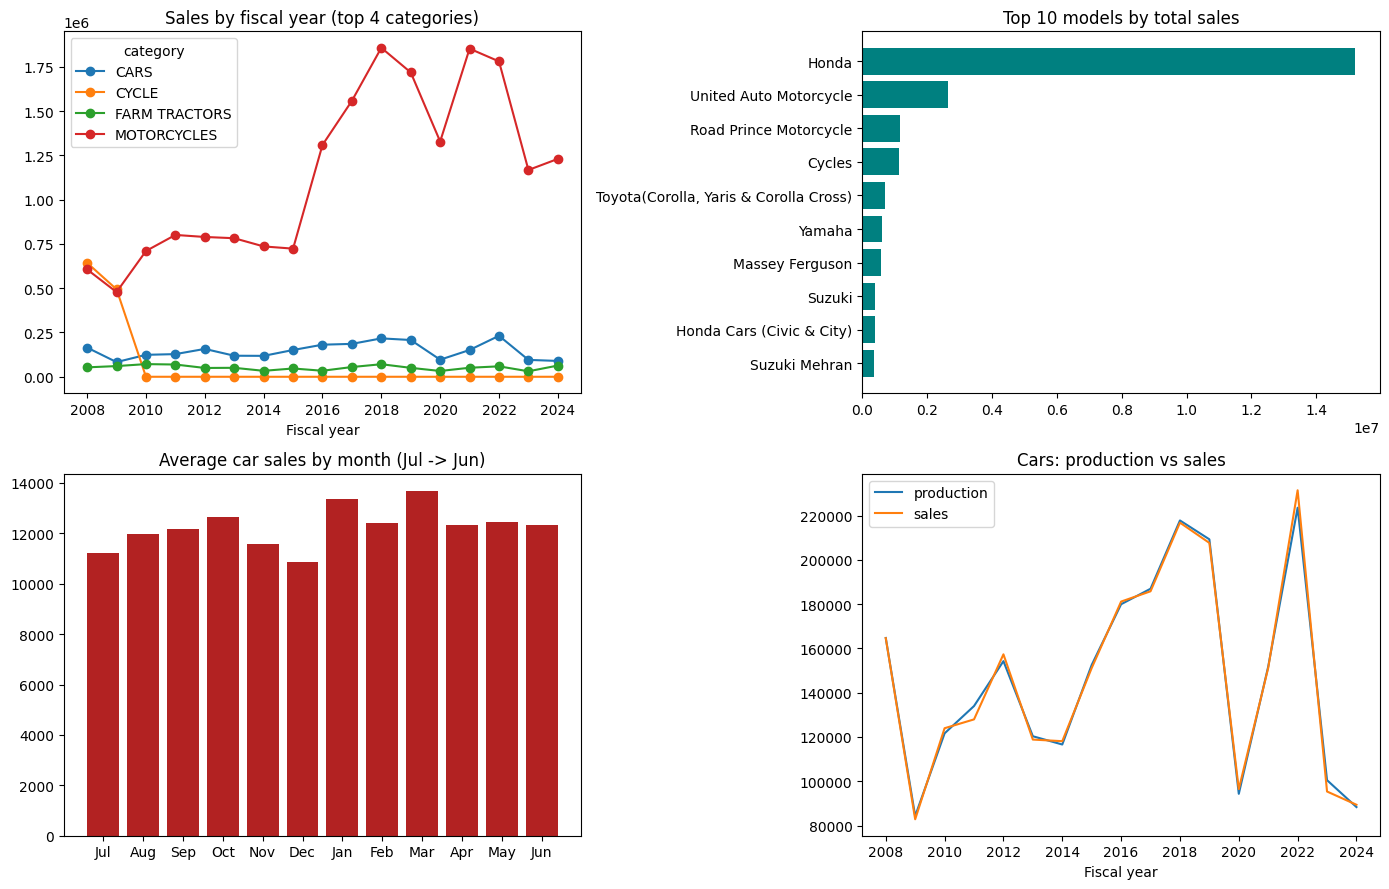

  fy  production  sales  gap_pct
2008      164710 164650      0.0
2009       84308  82844      1.8
2010      121647 123957     -1.9
2011      133972 127944      4.7
2012      154255 157325     -2.0
2013      120332 118830      1.3
2014      116605 118102     -1.3
2015      152524 151134      0.9
2016      179944 181145     -0.7
2017      186936 185781      0.6
2018      217774 216786      0.5
2019      209255 207630      0.8
2020       94325  96455     -2.2
2021      151794 151182      0.4
2022      223513 231398     -3.4
2023      100496  95378      5.4
2024       88355  89399     -1.2


In [6]:
def q(sql): return spark.sql(sql).toPandas()

# Q1: Sales by fiscal year and category
by_cat = q("""SELECT d.fiscal_year AS fy, v.category, SUM(f.sales) AS sales
              FROM fact_auto f JOIN dim_date d USING(date_key) JOIN dim_vehicle v USING(vehicle_key)
              WHERE d.is_full_fy GROUP BY d.fiscal_year, v.category""")
top_cats = by_cat.groupby("category")["sales"].sum().nlargest(4).index
piv = by_cat[by_cat.category.isin(top_cats)].pivot(index="fy", columns="category", values="sales").fillna(0)

# Q2: Top 10 models by total sales
top_models = q("""SELECT v.model, v.category, SUM(f.sales) AS total_sales
                  FROM fact_auto f JOIN dim_vehicle v USING(vehicle_key)
                  GROUP BY v.model, v.category ORDER BY total_sales DESC LIMIT 10""")

# Q3: Seasonality of CAR sales (average per month, fiscal order Jul -> Jun)
season = q("""SELECT month, month_name, ROUND(AVG(total),0) AS avg_car_sales FROM (
                SELECT d.month, d.month_name, d.date_key, SUM(f.sales) AS total
                FROM fact_auto f JOIN dim_date d USING(date_key) JOIN dim_vehicle v USING(vehicle_key)
                WHERE v.category = 'CARS' AND d.is_full_fy GROUP BY d.month, d.month_name, d.date_key)
              GROUP BY month, month_name
              ORDER BY CASE WHEN month >= 7 THEN month - 7 ELSE month + 5 END""")

# Q4: Production vs sales for CARS per fiscal year
gap = q("""SELECT d.fiscal_year AS fy, SUM(f.production) AS production, SUM(f.sales) AS sales
           FROM fact_auto f JOIN dim_date d USING(date_key) JOIN dim_vehicle v USING(vehicle_key)
           WHERE v.category = 'CARS' AND d.is_full_fy GROUP BY d.fiscal_year ORDER BY d.fiscal_year""")
gap["gap_pct"] = ((gap.production - gap.sales) / gap.sales * 100).round(1)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
piv.plot(ax=ax[0, 0], marker="o"); ax[0, 0].set_title("Sales by fiscal year (top 4 categories)"); ax[0, 0].set_xlabel("Fiscal year")
ax[0, 1].barh(top_models.model[::-1], top_models.total_sales[::-1], color="teal"); ax[0, 1].set_title("Top 10 models by total sales")
ax[1, 0].bar(season.month_name, season.avg_car_sales, color="firebrick"); ax[1, 0].set_title("Average car sales by month (Jul -> Jun)")
gap.set_index("fy")[["production", "sales"]].plot(ax=ax[1, 1]); ax[1, 1].set_title("Cars: production vs sales"); ax[1, 1].set_xlabel("Fiscal year")
plt.tight_layout(); plt.show()
print(gap.to_string(index=False))

## 5. Data mining A – KMeans: group vehicle models by selling behaviour
For each model we measure: **average monthly sales**, **volatility** (how unstable its sales are) and **months active**.
KMeans then finds groups (we pick the number of groups automatically) of similar models (no labels needed – *unsupervised learning*).

Models used for clustering: 50
k=2  silhouette=0.543
k=3  silhouette=0.539
k=4  silhouette=0.548
k=5  silhouette=0.560
Chosen k = 5

             models  avg_monthly_sales  volatility  active_months                                     group
prediction                                                                                                
4                7              36.03        1.26          66.29  Group 1 (volume rank 1 of 5, 1 = lowest)
0               13             315.33        0.70          82.62  Group 2 (volume rank 2 of 5, 1 = lowest)
3                6             337.36        1.23         159.67  Group 3 (volume rank 3 of 5, 1 = lowest)
1               17            5705.63        0.56         202.88  Group 4 (volume rank 4 of 5, 1 = lowest)
2                7           12420.21        0.55         101.43  Group 5 (volume rank 5 of 5, 1 = lowest)

Group 1 (volume rank 1 of 5, 1 = lowest) e.g.: ['Suzuki Liana', 'Hyundai Santro', 'Orient Imt Tractor', 'Isuzu D-Max

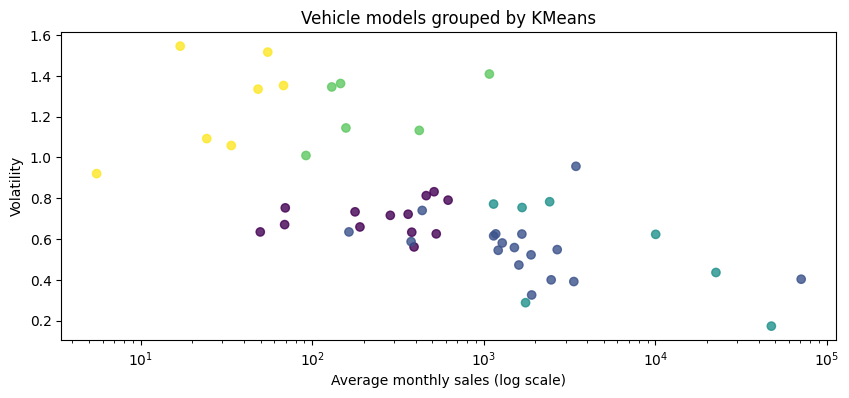

In [7]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

stats = spark.sql("""SELECT v.model, v.category, COUNT(*) AS active_months,
                            AVG(f.sales) AS avg_sales, STDDEV(f.sales) / AVG(f.sales) AS volatility
                     FROM fact_auto f JOIN dim_vehicle v USING(vehicle_key)
                     WHERE f.sales > 0 GROUP BY v.model, v.category HAVING COUNT(*) >= 24""").na.fill(0)
stats = stats.withColumn("log_avg_sales", F.log1p("avg_sales"))   # log tames huge size differences
print("Models used for clustering:", stats.count())

vec = VectorAssembler(inputCols=["log_avg_sales", "volatility", "active_months"], outputCol="raw").transform(stats)
vec = StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True).fit(vec).transform(vec)

# Choose k: try k = 2..5 and keep the one with the best silhouette score (higher = better separated)
scores = {}
for k in range(2, 6):
    scores[k] = ClusteringEvaluator(featuresCol="features").evaluate(
        KMeans(k=k, seed=42, featuresCol="features").fit(vec).transform(vec))
    print(f"k={k}  silhouette={scores[k]:.3f}")
best_k = max(scores, key=scores.get)
print("Chosen k =", best_k)

km = KMeans(k=best_k, seed=42, featuresCol="features").fit(vec)
res = km.transform(vec).select("model", "category", "avg_sales", "volatility", "active_months", "prediction").toPandas()

prof = (res.groupby("prediction").agg(models=("model", "count"), avg_monthly_sales=("avg_sales", "mean"),
                                      volatility=("volatility", "mean"), active_months=("active_months", "mean"))
           .round(2).sort_values("avg_monthly_sales"))
prof["group"] = [f"Group {i+1} (volume rank {i+1} of {best_k}, 1 = lowest)" for i in range(best_k)]
print("\n", prof.to_string())
for p, row in prof.iterrows():
    names = res[res.prediction == p].sort_values("avg_sales", ascending=False).model.head(6).tolist()
    print(f"\n{row['group']} e.g.: {names}")

plt.scatter(res.avg_sales, res.volatility, c=res.prediction, cmap="viridis", alpha=.8)
plt.xscale("log"); plt.xlabel("Average monthly sales (log scale)"); plt.ylabel("Volatility")
plt.title("Vehicle models grouped by KMeans"); plt.show()

## 6. Data mining B – Forecast monthly car sales (Random Forest)
Features: sales **1 month ago**, **2 months ago**, **12 months ago** (same month last year) and the **calendar month**.
We train on older months and test on the **last 12 months**, and compare with two simple baselines. A model is only useful if it beats them.

Train months: 191 | Test months: 12 (from 2024-06-01)
Random Forest                  : RMSE     4125 | MAPE  26.3%
Baseline 'same as last month'  : RMSE     4402 | MAPE  31.6%
Baseline 'same month last year': RMSE     7029 | MAPE  37.4%
Feature importance: {'lag1': 0.483, 'lag2': 0.325, 'lag12': 0.116, 'month': 0.076}


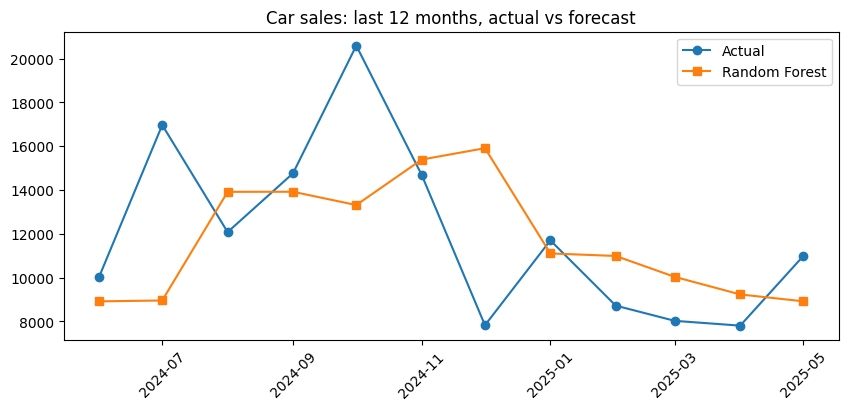

In [8]:
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

monthly = spark.sql("""SELECT d.date, d.month, SUM(f.sales) AS sales
                       FROM fact_auto f JOIN dim_date d USING(date_key) JOIN dim_vehicle v USING(vehicle_key)
                       WHERE v.category = 'CARS' GROUP BY d.date, d.month ORDER BY d.date""")
w = Window.orderBy("date")
feat = (monthly.withColumn("lag1", F.lag("sales", 1).over(w))
               .withColumn("lag2", F.lag("sales", 2).over(w))
               .withColumn("lag12", F.lag("sales", 12).over(w)).dropna())
feat = VectorAssembler(inputCols=["lag1", "lag2", "lag12", "month"], outputCol="features").transform(feat)

dates = [r["date"] for r in feat.select("date").orderBy("date").collect()]
split = dates[-12]                                   # last 12 months = test set
train, test = feat.filter(F.col("date") < split), feat.filter(F.col("date") >= split)
print(f"Train months: {train.count()} | Test months: {test.count()} (from {split})")

rf = RandomForestRegressor(featuresCol="features", labelCol="sales", numTrees=200, maxDepth=6, seed=42).fit(train)
pred = rf.transform(test)

p = pred.select("date", "sales", "prediction", "lag1", "lag12").orderBy("date").toPandas().astype({"sales": float, "lag1": float, "lag12": float})
rmse = lambda a, b: float(np.sqrt(((a - b) ** 2).mean()))
mape = lambda a, b: float((abs(a - b) / a).mean() * 100)
print(f"Random Forest                  : RMSE {rmse(p.sales, p.prediction):8.0f} | MAPE {mape(p.sales, p.prediction):5.1f}%")
print(f"Baseline 'same as last month'  : RMSE {rmse(p.sales, p.lag1):8.0f} | MAPE {mape(p.sales, p.lag1):5.1f}%")
print(f"Baseline 'same month last year': RMSE {rmse(p.sales, p.lag12):8.0f} | MAPE {mape(p.sales, p.lag12):5.1f}%")
print("Feature importance:", dict(zip(["lag1", "lag2", "lag12", "month"], [round(float(v), 3) for v in rf.featureImportances.toArray()])))

plt.plot(p.date, p.sales, marker="o", label="Actual"); plt.plot(p.date, p.prediction, marker="s", label="Random Forest")
plt.title("Car sales: last 12 months, actual vs forecast"); plt.legend(); plt.xticks(rotation=45); plt.show()

## 7. Findings (computed from your results)

In [9]:
tot = by_cat.groupby("fy")["sales"].sum()
yoy = (tot.pct_change() * 100).round(1)
print(f"Peak year: FY{tot.idxmax()} with {tot.max():,.0f} vehicles sold (FY2008-FY2024).")
print(f"Biggest yearly drop: FY{yoy.idxmin()} ({yoy.min()}%). Biggest yearly rise: FY{yoy.idxmax()} (+{yoy.max()}%).")
print(f"Best month for car sales: {season.loc[season.avg_car_sales.idxmax(), 'month_name']} | weakest: {season.loc[season.avg_car_sales.idxmin(), 'month_name']}.")
over = gap[gap.gap_pct > 0]
print(f"Cars: production exceeded sales in {len(over)} of {len(gap)} fiscal years.")
print("\nYearly change in total sales (%):"); print(yoy.dropna().to_string())

Peak year: FY2018 with 2,271,112 vehicles sold (FY2008-FY2024).
Biggest yearly drop: FY2023 (-37.8%). Biggest yearly rise: FY2016 (+62.0%).
Best month for car sales: Mar | weakest: Dec.
Cars: production exceeded sales in 9 of 17 fiscal years.

Yearly change in total sales (%):
fy
2009   -24.9
2010   -17.0
2011    10.4
2012     0.7
2013    -5.0
2014    -6.2
2015     5.5
2016    62.0
2017    18.0
2018    19.1
2019    -8.4
2020   -27.0
2021    41.0
2022     1.2
2023   -37.8
2024     6.8
